# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "BONDAR"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [3]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

Saving train.csv to train.csv
Saving weather_forecast.csv to weather_forecast.csv
history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [4]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [5]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

In [6]:
# Rolling validation: 10 windows, 48 hours each

N_WINDOWS = 10
STEP = 7 * 24

origins = range(
    len(y) - H - (N_WINDOWS - 1) * STEP,
    len(y) - H + 1,
    STEP
)

validation_results = []

for cutoff in origins:
    past = y[:cutoff]
    actual = y[cutoff:cutoff + H]

    benchmark = snaive(past)

    metrics = score(actual, *benchmark)

    validation_results.append(metrics)

validation_scores = pd.DataFrame(validation_results)

print("Results for 10 validation windows:")
display(validation_scores)

print("\nAverage scores:")
display(validation_scores.mean().to_frame("Mean"))

print("\nStandard deviation:")
display(validation_scores.std().to_frame("Std"))

Results for 10 validation windows:


,RMSE,MAPE,Winkler,coverage
0,124.897,9.578,736.538,0.979
1,233.207,218.101,867.381,0.875
2,315.989,43.630,2234.353,0.792
3,458.283,151.364,4823.736,0.438
4,268.776,60.795,1545.289,0.833
5,403.203,227.873,3380.294,0.604
6,674.407,131.594,9534.853,0.625
7,242.828,27.703,1661.696,0.875
8,545.794,8741.039,6863.548,0.396
9,120.404,51.088,568.464,1.000



Average scores:


,Mean
RMSE,338.779
MAPE,966.276
Winkler,3221.615
coverage,0.742



Standard deviation:


,Std
RMSE,180.474
MAPE,2732.879
Winkler,2994.216
coverage,0.215


In [7]:
import importlib.util

libraries = ["lightgbm", "xgboost", "catboost", "sklearn"]

for library in libraries:
    installed = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if installed else 'Not installed'}")

lightgbm: Installed
xgboost: Installed
catboost: Not installed
sklearn: Installed


In [8]:
# Feature engineering for LightGBM

def make_features(y, ds, origins, max_horizon=48):

    rows = []

    lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
    windows = [24, 48, 168]

    for origin in origins:

        if origin < 336:
            continue

        history = np.asarray(y[:origin + 1], dtype=float)

        for h in range(1, max_horizon + 1):

            target_idx = origin + h

            if target_idx >= len(ds):
                continue

            target_time = ds.iloc[target_idx]

            row = {
                "origin_idx": origin,
                "horizon": h,

                # Calendar features
                "hour": target_time.hour,
                "dayofweek": target_time.dayofweek,
                "month": target_time.month,
                "dayofyear": target_time.dayofyear,

                # Cyclical features
                "hour_sin": np.sin(2 * np.pi * target_time.hour / 24),
                "hour_cos": np.cos(2 * np.pi * target_time.hour / 24),

                "day_sin": np.sin(2 * np.pi * target_time.dayofweek / 7),
                "day_cos": np.cos(2 * np.pi * target_time.dayofweek / 7),

                "year_sin": np.sin(2 * np.pi * target_time.dayofyear / 365.25),
                "year_cos": np.cos(2 * np.pi * target_time.dayofyear / 365.25),
            }

            # Lag features
            for lag in lags:
                row[f"lag_{lag}"] = history[-1 - lag]

            # Rolling statistics
            for window in windows:
                values = history[-window:]

                row[f"rolling_mean_{window}"] = np.mean(values)
                row[f"rolling_std_{window}"] = np.std(values)

            rows.append(row)

    return pd.DataFrame(rows)

In [9]:
# Create a small sample of training features

sample_origins = range(336, 1000, 6)

sample_features = make_features(
    y=data["y"].to_numpy(dtype=float),
    ds=data["ds"],
    origins=sample_origins
)

print("Feature dataset shape:", sample_features.shape)

display(sample_features.head())

Feature dataset shape: (5328, 29)


,origin_idx,horizon,hour,dayofweek,month,dayofyear,hour_sin,hour_cos,day_sin,day_cos,...,lag_48,lag_72,lag_168,lag_336,rolling_mean_24,rolling_std_24,rolling_mean_48,rolling_std_48,rolling_mean_168,rolling_std_168
0,336,1,2,6,1,15,0.500,8.660e-01,-0.782,0.623,...,163.0,38.4,280.8,30.1,64.333,60.685,67.213,68.446,163.79,118.107
1,336,2,3,6,1,15,0.707,7.071e-01,-0.782,0.623,...,163.0,38.4,280.8,30.1,64.333,60.685,67.213,68.446,163.79,118.107
2,336,3,4,6,1,15,0.866,5.000e-01,-0.782,0.623,...,163.0,38.4,280.8,30.1,64.333,60.685,67.213,68.446,163.79,118.107
3,336,4,5,6,1,15,0.966,2.588e-01,-0.782,0.623,...,163.0,38.4,280.8,30.1,64.333,60.685,67.213,68.446,163.79,118.107
4,336,5,6,6,1,15,1.000,6.123e-17,-0.782,0.623,...,163.0,38.4,280.8,30.1,64.333,60.685,67.213,68.446,163.79,118.107


In [10]:
# Step 3: Train the first LightGBM model

import lightgbm as lgb

# Prepare data
y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

cutoff = len(y_array) - H

# Training origins: every 24 hours
train_origins = range(336, cutoff - H, 24)

# Create training features
train_features = make_features(
    y=y_array,
    ds=ds,
    origins=train_origins
)

# Create validation features
valid_features = make_features(
    y=y_array,
    ds=ds,
    origins=[cutoff - 1]
)

# Extract target values
target_indices = (
    train_features["origin_idx"].to_numpy()
    + train_features["horizon"].to_numpy()
)

y_train = y_array[target_indices]

# Remove technical column
X_train = train_features.drop(columns=["origin_idx"])
X_valid = valid_features.drop(columns=["origin_idx"])

# Train model
model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

model.fit(X_train, y_train)

# Generate 48-hour forecast
forecast_lgb = model.predict(X_valid)

# Actual values
actual = y_array[cutoff:]

# Benchmark
past = y_array[:cutoff]
bench = snaive(past)

# Compare RMSE
print("LightGBM RMSE:", round(rmse(actual, forecast_lgb), 3))
print("SNAIVE RMSE:", round(rmse(actual, bench[0]), 3))

print(
    "RMSE improvement:",
    round(
        (1 - rmse(actual, forecast_lgb) / rmse(actual, bench[0])) * 100,
        2
    ),
    "%"
)

LightGBM RMSE: 158.608
SNAIVE RMSE: 120.404
RMSE improvement: -31.73 %


In [11]:
# Step 4: Rolling validation for LightGBM

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

lgb_results = []

for i, cutoff in enumerate(origins):

    print(f"Training window {i + 1}/{len(origins)}...")

    # Training origins
    train_origins = range(336, cutoff - H, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins
    )

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1]
    )

    # Training targets
    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    y_train = y_array[target_indices]

    # Prepare features
    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train model
    model = lgb.LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=30,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1
    )

    model.fit(X_train, y_train)

    # Forecast
    forecast = model.predict(X_valid)

    # Actual values
    actual = y_array[cutoff:cutoff + H]

    # SNAIVE benchmark
    benchmark = snaive(y_array[:cutoff])[0]

    # Calculate RMSE
    lgb_rmse = np.sqrt(np.mean((actual - forecast) ** 2))
    naive_rmse = np.sqrt(np.mean((actual - benchmark) ** 2))

    lgb_results.append({
        "Window": i + 1,
        "LightGBM_RMSE": lgb_rmse,
        "SNAIVE_RMSE": naive_rmse,
        "Improvement_%": (1 - lgb_rmse / naive_rmse) * 100
    })

# Results table
lgb_validation = pd.DataFrame(lgb_results)

display(lgb_validation.round(3))

print("\nAverage results:")
display(lgb_validation.mean(numeric_only=True).to_frame("Mean").round(3))

Training window 1/10...
Training window 2/10...
Training window 3/10...
Training window 4/10...
Training window 5/10...
Training window 6/10...
Training window 7/10...
Training window 8/10...
Training window 9/10...
Training window 10/10...


,Window,LightGBM_RMSE,SNAIVE_RMSE,Improvement_%
0,1,232.995,124.897,-86.550
1,2,251.572,233.207,-7.875
2,3,235.789,315.989,25.381
3,4,419.668,458.283,8.426
4,5,204.521,268.776,23.907
5,6,429.128,403.203,-6.430
6,7,390.783,674.407,42.055
7,8,321.143,242.828,-32.251
8,9,229.377,545.794,57.974
9,10,158.608,120.404,-31.730



Average results:


,Mean
Window,5.500
LightGBM_RMSE,287.358
SNAIVE_RMSE,338.779
Improvement_%,-0.709


In [12]:
# Step 5: XGBoost Rolling Validation

import xgboost as xgb

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

xgb_results = []

for i, cutoff in enumerate(origins):

    print(f"Training XGBoost window {i + 1}/{len(origins)}...")

    # Training origins
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins
    )

    # Remove training examples with targets in validation period
    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    valid_mask = target_indices < cutoff

    train_features = train_features.loc[valid_mask].reset_index(drop=True)
    target_indices = target_indices[valid_mask]

    y_train = y_array[target_indices]

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1]
    )

    # Prepare datasets
    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train XGBoost
    model = xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    # Forecast
    forecast = model.predict(X_valid)

    # Actual values
    actual = y_array[cutoff:cutoff + H]

    # SNAIVE benchmark
    benchmark = snaive(y_array[:cutoff])[0]

    # Metrics
    xgb_rmse = np.sqrt(np.mean((actual - forecast) ** 2))
    naive_rmse = np.sqrt(np.mean((actual - benchmark) ** 2))

    improvement = (1 - xgb_rmse / naive_rmse) * 100

    xgb_results.append({
        "Window": i + 1,
        "XGBoost_RMSE": xgb_rmse,
        "SNAIVE_RMSE": naive_rmse,
        "Improvement_%": improvement
    })

# Results
xgb_validation = pd.DataFrame(xgb_results)

print("\nXGBoost Rolling Validation:")
display(xgb_validation.round(3))

print("\nAverage Results:")
display(
    xgb_validation.drop(columns="Window")
    .mean()
    .to_frame("Mean")
    .round(3)
)

print(
    "\nWindows won by XGBoost:",
    (xgb_validation["Improvement_%"] > 0).sum(),
    "/ 10"
)

Training XGBoost window 1/10...
Training XGBoost window 2/10...
Training XGBoost window 3/10...
Training XGBoost window 4/10...
Training XGBoost window 5/10...
Training XGBoost window 6/10...
Training XGBoost window 7/10...
Training XGBoost window 8/10...
Training XGBoost window 9/10...
Training XGBoost window 10/10...

XGBoost Rolling Validation:


,Window,XGBoost_RMSE,SNAIVE_RMSE,Improvement_%
0,1,145.294,124.897,-16.331
1,2,199.116,233.207,14.619
2,3,247.280,315.989,21.744
3,4,414.978,458.283,9.450
4,5,217.516,268.776,19.072
5,6,393.254,403.203,2.468
6,7,462.817,674.407,31.374
7,8,187.358,242.828,22.843
8,9,222.800,545.794,59.179
9,10,110.203,120.404,8.473



Average Results:


,Mean
XGBoost_RMSE,260.062
SNAIVE_RMSE,338.779
Improvement_%,17.289



Windows won by XGBoost: 9 / 10


In [13]:
# Step 6: XGBoost evaluation with RMSE and MAPE

import xgboost as xgb

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

xgb_results = []

for i, cutoff in enumerate(origins):

    print(f"Evaluating window {i + 1}/10...")

    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1]
    )

    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    model = xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    forecast = model.predict(X_valid)
    actual = y_array[cutoff:cutoff + H]

    benchmark = snaive(y_array[:cutoff])[0]

    xgb_results.append({
        "Window": i + 1,
        "XGBoost_RMSE": rmse(actual, forecast),
        "SNAIVE_RMSE": rmse(actual, benchmark),
        "XGBoost_MAPE": mape(actual, forecast),
        "SNAIVE_MAPE": mape(actual, benchmark)
    })

xgb_metrics = pd.DataFrame(xgb_results)

print("Results for all validation windows:")
display(xgb_metrics.round(3))

print("\nAverage metrics:")
display(
    xgb_metrics.drop(columns="Window")
    .mean()
    .to_frame("Mean")
    .round(3)
)

Evaluating window 1/10...
Evaluating window 2/10...
Evaluating window 3/10...
Evaluating window 4/10...
Evaluating window 5/10...
Evaluating window 6/10...
Evaluating window 7/10...
Evaluating window 8/10...
Evaluating window 9/10...
Evaluating window 10/10...
Results for all validation windows:


,Window,XGBoost_RMSE,SNAIVE_RMSE,XGBoost_MAPE,SNAIVE_MAPE
0,1,145.294,124.897,15.113,9.578
1,2,199.116,233.207,131.089,218.101
2,3,247.280,315.989,24.290,43.630
3,4,414.978,458.283,107.537,151.364
4,5,217.516,268.776,30.255,60.795
5,6,393.254,403.203,248.048,227.873
6,7,462.817,674.407,97.580,131.594
7,8,187.358,242.828,27.296,27.703
8,9,222.800,545.794,3254.394,8741.039
9,10,110.203,120.404,65.878,51.088



Average metrics:


,Mean
XGBoost_RMSE,260.062
SNAIVE_RMSE,338.779
XGBoost_MAPE,400.148
SNAIVE_MAPE,966.276


In [14]:
# Feature engineering for historical and future forecasts

def make_features(y, ds, origins, max_horizon=48, weather=None):

    rows = []

    lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
    windows = [24, 48, 168]

    for origin in origins:

        if origin < 336:
            continue

        history = np.asarray(y[:origin + 1], dtype=float)

        for h in range(1, max_horizon + 1):

            target_idx = origin + h

            if weather is not None:
                target_time = pd.to_datetime(weather.iloc[h - 1]["ds"])
            else:
                if target_idx >= len(ds):
                    continue
                target_time = pd.to_datetime(ds.iloc[target_idx])

            row = {
                "origin_idx": origin,
                "horizon": h,
                "hour": target_time.hour,
                "dayofweek": target_time.dayofweek,
                "month": target_time.month,
                "dayofyear": target_time.dayofyear,
                "hour_sin": np.sin(2 * np.pi * target_time.hour / 24),
                "hour_cos": np.cos(2 * np.pi * target_time.hour / 24),
                "day_sin": np.sin(2 * np.pi * target_time.dayofweek / 7),
                "day_cos": np.cos(2 * np.pi * target_time.dayofweek / 7),
                "year_sin": np.sin(2 * np.pi * target_time.dayofyear / 365.25),
                "year_cos": np.cos(2 * np.pi * target_time.dayofyear / 365.25),
            }

            for lag in lags:
                row[f"lag_{lag}"] = history[-1 - lag]

            for window in windows:
                values = history[-window:]
                row[f"rolling_mean_{window}"] = np.mean(values)
                row[f"rolling_std_{window}"] = np.std(values)

            if weather is not None:
                for col in [
                    "cloud_cover",
                    "temperature",
                    "wind_speed",
                    "pressure",
                    "humidity",
                    "daylight",
                    "air_density"
                ]:
                    row[col] = weather.iloc[h - 1][col]

            rows.append(row)

    return pd.DataFrame(rows)

In [15]:
# Check weather data

weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

print("Historical weather:")
display(data[weather_cols].describe().round(2))

print("\nFuture weather forecast:")
display(weather_fc[weather_cols].head(10))

Historical weather:


,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
count,33480.00,33480.00,33480.00,33480.00,33480.00,33480.00,33480.00
mean,0.60,12.22,3.73,757.66,71.70,0.47,1.24
std,0.42,10.66,2.33,5.54,21.18,0.50,0.05
min,0.00,-19.00,0.00,736.00,7.00,0.00,1.12
25%,0.25,4.00,2.00,754.00,56.00,0.00,1.20
50%,0.75,12.00,3.00,757.00,77.00,0.00,1.24
75%,1.00,21.00,5.00,761.00,89.00,1.00,1.28
max,1.00,39.00,14.00,775.00,100.00,1.00,1.41



Future weather forecast:


,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,1.00,8,4,763,100,0,1.263
1,1.00,6,3,763,99,0,1.268
2,1.00,4,3,763,99,0,1.270
3,1.00,5,3,764,100,0,1.266
4,1.00,7,3,764,97,0,1.264
5,0.75,6,3,764,97,0,1.271
6,1.00,7,3,764,100,1,1.281
7,1.00,9,3,763,100,1,1.258
8,1.00,7,3,763,100,1,1.258
9,0.75,10,3,763,100,1,1.262


In [18]:
print("Type:", type(data))
print("Columns:", data.columns.tolist())
print("\nFirst rows:")
display(data.head())

Type: <class 'pandas.core.frame.DataFrame'>
Columns: ['ds', 'y', 'cloud_cover', 'temperature', 'wind_speed', 'pressure', 'humidity', 'daylight', 'air_density']

First rows:


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,2023-01-01 01:00:00,30.1,0.0,-7,1,765,96,0,1.338
1,2023-01-01 02:00:00,30.1,0.0,-7,1,765,96,0,1.338
2,2023-01-01 03:00:00,19.2,0.0,-7,1,765,96,0,1.338
3,2023-01-01 04:00:00,15.1,0.0,-7,1,765,96,0,1.338
4,2023-01-01 05:00:00,21.9,0.0,-8,1,765,95,0,1.343


In [19]:
# Restore original data variables

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"].reset_index(drop=True)

weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

weather = data[weather_cols].reset_index(drop=True)

print("ds type:", type(ds))
print("ds length:", len(ds))
print("First date:", ds.iloc[0])
print("Weather shape:", weather.shape)

ds type: <class 'pandas.core.series.Series'>
ds length: 33480
First date: 2023-01-01 01:00:00
Weather shape: (33480, 7)


In [20]:
# Step 7: XGBoost with Weather Features

import xgboost as xgb

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

# Historical observed weather
weather = data[weather_cols].reset_index(drop=True)

weather_results = []

for i, cutoff in enumerate(origins):

    print(f"Training weather model: window {i + 1}/10")

    # Training origins
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    # Remove targets from validation period
    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    # Prepare features
    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train XGBoost
    model = xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    # Forecast
    forecast = model.predict(X_valid)

    actual = y_array[cutoff:cutoff + H]

    # Benchmark
    benchmark = snaive(y_array[:cutoff])[0]

    weather_results.append({
        "Window": i + 1,
        "Weather_RMSE": rmse(actual, forecast),
        "SNAIVE_RMSE": rmse(actual, benchmark),
        "Weather_MAPE": mape(actual, forecast),
        "SNAIVE_MAPE": mape(actual, benchmark)
    })

# Results
weather_validation = pd.DataFrame(weather_results)

print("\nXGBoost + Weather:")
display(weather_validation.round(3))

print("\nAverage metrics:")
display(
    weather_validation.drop(columns="Window")
    .mean()
    .to_frame("Mean")
    .round(3)
)

print("\nWindows won by XGBoost + Weather (RMSE):",
      (weather_validation["Weather_RMSE"] <
       weather_validation["SNAIVE_RMSE"]).sum(), "/ 10")

print("\nWindows won by XGBoost + Weather (MAPE):",
      (weather_validation["Weather_MAPE"] <
       weather_validation["SNAIVE_MAPE"]).sum(), "/ 10")

Training weather model: window 1/10


KeyError: 'ds'

In [22]:
# Feature engineering for historical validation and future forecasting

def make_features(y, ds, origins, max_horizon=48, weather=None):

    rows = []

    lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
    windows = [24, 48, 168]

    for origin in origins:

        if origin < 336:
            continue

        history = np.asarray(y[:origin + 1], dtype=float)

        for h in range(1, max_horizon + 1):

            target_idx = origin + h

            # Historical validation or future forecast
            if target_idx < len(ds):
                target_time = pd.to_datetime(ds.iloc[target_idx])
                weather_idx = target_idx
            else:
                if weather is None or "ds" not in weather.columns:
                    continue

                weather_idx = h - 1
                target_time = pd.to_datetime(
                    weather.iloc[weather_idx]["ds"]
                )

            row = {
                "origin_idx": origin,
                "horizon": h,
                "hour": target_time.hour,
                "dayofweek": target_time.dayofweek,
                "month": target_time.month,
                "dayofyear": target_time.dayofyear,
                "hour_sin": np.sin(2 * np.pi * target_time.hour / 24),
                "hour_cos": np.cos(2 * np.pi * target_time.hour / 24),
                "day_sin": np.sin(2 * np.pi * target_time.dayofweek / 7),
                "day_cos": np.cos(2 * np.pi * target_time.dayofweek / 7),
                "year_sin": np.sin(2 * np.pi * target_time.dayofyear / 365.25),
                "year_cos": np.cos(2 * np.pi * target_time.dayofyear / 365.25),
            }

            for lag in lags:
                row[f"lag_{lag}"] = history[-1 - lag]

            for window in windows:
                values = history[-window:]
                row[f"rolling_mean_{window}"] = np.mean(values)
                row[f"rolling_std_{window}"] = np.std(values)

            if weather is not None:
                for col in [
                    "cloud_cover",
                    "temperature",
                    "wind_speed",
                    "pressure",
                    "humidity",
                    "daylight",
                    "air_density"
                ]:
                    row[col] = weather.iloc[weather_idx][col]

            rows.append(row)

    return pd.DataFrame(rows)

In [23]:
# Step 17: XGBoost Hyperparameter Tuning
import xgboost as xgb

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"].reset_index(drop=True)
weather = data[weather_cols].reset_index(drop=True)

# Four configurations: baseline + three alternatives
configurations = {
    "Baseline": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 5,
        "reg_lambda": 5
    },
    "Shallower_Trees": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 4,
        "min_child_weight": 5,
        "reg_lambda": 5
    },
    "More_Regularization": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 10,
        "reg_lambda": 10
    },
    "More_Trees": {
        "n_estimators": 900,
        "learning_rate": 0.02,
        "max_depth": 6,
        "min_child_weight": 5,
        "reg_lambda": 5
    }
}

tuning_results = []

for config_name, params in configurations.items():

    print(f"\nTesting configuration: {config_name}")

    window_results = []

    for i, cutoff in enumerate(origins):

        print(f"  Window {i + 1}/10")

        # Training features
        train_origins = range(336, cutoff, 24)

        train_features = make_features(
            y=y_array,
            ds=ds,
            origins=train_origins,
            weather=weather
        )

        target_indices = (
            train_features["origin_idx"].to_numpy()
            + train_features["horizon"].to_numpy()
        )

        mask = target_indices < cutoff

        train_features = train_features.loc[mask].reset_index(drop=True)
        target_indices = target_indices[mask]

        y_train = y_array[target_indices]

        # Validation features
        valid_features = make_features(
            y=y_array,
            ds=ds,
            origins=[cutoff - 1],
            weather=weather
        )

        X_train = train_features.drop(columns=["origin_idx"])
        X_valid = valid_features.drop(columns=["origin_idx"])

        # Train model
        model = xgb.XGBRegressor(
            **params,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        # Forecast and evaluation
        forecast = model.predict(X_valid)
        actual = y_array[cutoff:cutoff + H]

        window_results.append({
            "RMSE": rmse(actual, forecast),
            "MAPE": mape(actual, forecast)
        })

    # Average metrics for this configuration
    results_df = pd.DataFrame(window_results)

    tuning_results.append({
        "Configuration": config_name,
        "Mean_RMSE": results_df["RMSE"].mean(),
        "Mean_MAPE": results_df["MAPE"].mean(),
        "RMSE_Wins": (
            results_df["RMSE"].to_numpy()
            < np.array([
                rmse(
                    y_array[c:c + H],
                    snaive(y_array[:c])[0]
                )
                for c in origins
            ])
        ).sum()
    })

# Compare configurations
tuning_comparison = pd.DataFrame(tuning_results)

tuning_comparison = tuning_comparison.sort_values(
    "Mean_RMSE"
).reset_index(drop=True)

print("\nXGBoost Hyperparameter Comparison:")
display(tuning_comparison.round(3))

print("\nBest configuration by RMSE:")
print(tuning_comparison.iloc[0]["Configuration"])

print("\nBest configuration by MAPE:")
print(
    tuning_comparison.loc[
        tuning_comparison["Mean_MAPE"].idxmin(),
        "Configuration"
    ]
)


Testing configuration: Baseline
  Window 1/10
  Window 2/10
  Window 3/10
  Window 4/10
  Window 5/10
  Window 6/10
  Window 7/10
  Window 8/10
  Window 9/10
  Window 10/10

Testing configuration: Shallower_Trees
  Window 1/10
  Window 2/10
  Window 3/10
  Window 4/10
  Window 5/10
  Window 6/10
  Window 7/10
  Window 8/10
  Window 9/10
  Window 10/10

Testing configuration: More_Regularization
  Window 1/10
  Window 2/10
  Window 3/10
  Window 4/10
  Window 5/10
  Window 6/10
  Window 7/10
  Window 8/10
  Window 9/10
  Window 10/10

Testing configuration: More_Trees
  Window 1/10
  Window 2/10
  Window 3/10
  Window 4/10
  Window 5/10
  Window 6/10
  Window 7/10
  Window 8/10
  Window 9/10
  Window 10/10

XGBoost Hyperparameter Comparison:


,Configuration,Mean_RMSE,Mean_MAPE,RMSE_Wins
0,More_Regularization,205.511,431.964,9
1,More_Trees,207.633,416.830,9
2,Baseline,209.008,425.180,9
3,Shallower_Trees,215.878,422.155,9



Best configuration by RMSE:
More_Regularization

Best configuration by MAPE:
More_Trees


In [24]:
# Step 18: Compare prediction intervals for tuned XGBoost models

import xgboost as xgb

# Configurations selected from Step 17
interval_configs = {
    "More_Regularization": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 10,
        "reg_lambda": 10
    },
    "More_Trees": {
        "n_estimators": 900,
        "learning_rate": 0.02,
        "max_depth": 6,
        "min_child_weight": 5,
        "reg_lambda": 5
    }
}

# Store predictions and residuals
config_predictions = {
    name: [] for name in interval_configs
}

config_residuals = {
    name: [] for name in interval_configs
}

interval_results = []

for i, cutoff in enumerate(origins):

    print(f"\nValidation window {i + 1}/10")

    actual = y_array[cutoff:cutoff + H]

    # Training data
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    X_train = train_features.drop(columns=["origin_idx"])

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train both configurations
    for name, params in interval_configs.items():

        model = xgb.XGBRegressor(
            **params,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        forecast = model.predict(X_valid)

        config_predictions[name].append(forecast)

        # Calibrate using previous validation windows only
        if i >= 2:

            previous_errors = np.concatenate(
                config_residuals[name]
            )

            lower_error = np.quantile(previous_errors, 0.025)
            upper_error = np.quantile(previous_errors, 0.975)

            lower = np.maximum(0, forecast + lower_error)
            upper = np.maximum(forecast, forecast + upper_error)

            metrics = score(actual, forecast, lower, upper)

            interval_results.append({
                "Window": i + 1,
                "Configuration": name,
                "RMSE": metrics["RMSE"],
                "MAPE": metrics["MAPE"],
                "Winkler": metrics["Winkler"],
                "Coverage": metrics["coverage"],
                "Interval_Width": np.mean(upper - lower)
            })

        # Save errors for subsequent windows
        config_residuals[name].append(actual - forecast)


# Results
interval_comparison = pd.DataFrame(interval_results)

print("\nResults for validation windows 3-10:")
display(interval_comparison.round(3))

print("\nAverage metrics by configuration:")

summary = interval_comparison.groupby("Configuration")[
    ["RMSE", "MAPE", "Winkler", "Coverage", "Interval_Width"]
].mean()

display(summary.round(3))

print("\nBest configuration by Winkler:")
print(summary["Winkler"].idxmin())

print("\nBest configuration by RMSE:")
print(summary["RMSE"].idxmin())

print("\nBest configuration by MAPE:")
print(summary["MAPE"].idxmin())


Validation window 1/10

Validation window 2/10

Validation window 3/10

Validation window 4/10

Validation window 5/10

Validation window 6/10

Validation window 7/10

Validation window 8/10

Validation window 9/10

Validation window 10/10

Results for validation windows 3-10:


,Window,Configuration,RMSE,MAPE,Winkler,Coverage,Interval_Width
0,3,More_Regularization,207.545,16.559,1279.164,0.854,558.180
1,3,More_Trees,210.967,20.671,1564.480,0.812,505.494
2,4,More_Regularization,318.287,109.157,3759.350,0.479,678.129
3,4,More_Trees,346.657,123.268,5198.287,0.396,662.418
4,5,More_Regularization,187.705,29.616,930.737,0.958,765.043
5,5,More_Trees,189.844,28.627,986.537,0.917,777.715
6,6,More_Regularization,198.449,175.513,724.569,1.000,724.569
7,6,More_Trees,203.073,176.178,768.788,1.000,768.788
8,7,More_Regularization,302.018,95.408,1489.235,0.771,761.579
9,7,More_Trees,324.709,94.669,1497.055,0.812,822.816



Average metrics by configuration:


,RMSE,MAPE,Winkler,Coverage,Interval_Width
Configuration,,,,,
More_Regularization,216.734,520.507,1312.418,0.875,701.221
More_Trees,221.321,503.284,1544.473,0.862,717.939



Best configuration by Winkler:
More_Regularization

Best configuration by RMSE:
More_Regularization

Best configuration by MAPE:
More_Trees


In [25]:
# Step 19: Fair comparison of Baseline and More Regularization

import xgboost as xgb

final_configs = {
    "Baseline": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 5,
        "reg_lambda": 5
    },
    "More_Regularization": {
        "n_estimators": 600,
        "learning_rate": 0.03,
        "max_depth": 6,
        "min_child_weight": 10,
        "reg_lambda": 10
    }
}

final_predictions = {
    name: [] for name in final_configs
}

final_residuals = {
    name: [] for name in final_configs
}

final_results = []

for i, cutoff in enumerate(origins):

    print(f"Validation window {i + 1}/10")

    actual = y_array[cutoff:cutoff + H]

    # Training data
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    X_train = train_features.drop(columns=["origin_idx"])

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train and evaluate both configurations
    for name, params in final_configs.items():

        model = xgb.XGBRegressor(
            **params,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        forecast = model.predict(X_valid)

        final_predictions[name].append(forecast)

        # Evaluate intervals on windows 3-10
        if i >= 2:

            previous_errors = np.concatenate(
                final_residuals[name]
            )

            lower_error = np.quantile(previous_errors, 0.025)
            upper_error = np.quantile(previous_errors, 0.975)

            lower = np.maximum(0, forecast + lower_error)
            upper = np.maximum(forecast, forecast + upper_error)

            metrics = score(actual, forecast, lower, upper)

            final_results.append({
                "Window": i + 1,
                "Configuration": name,
                "RMSE": rmse(actual, forecast),
                "MAPE": mape(actual, forecast),
                "Winkler": metrics["Winkler"],
                "Coverage": metrics["coverage"],
                "Interval_Width": np.mean(upper - lower)
            })

        # Save residuals for future windows
        final_residuals[name].append(actual - forecast)


# Comparison results
final_comparison = pd.DataFrame(final_results)

print("\nResults for identical validation windows (3-10):")
display(final_comparison.round(3))

print("\nAverage metrics:")
final_summary = final_comparison.groupby("Configuration")[
    ["RMSE", "MAPE", "Winkler", "Coverage", "Interval_Width"]
].mean()

display(final_summary.round(3))

print("\nBest configuration by each metric:")

for metric in ["RMSE", "MAPE", "Winkler"]:
    print(metric, ":", final_summary[metric].idxmin())

Validation window 1/10
Validation window 2/10
Validation window 3/10
Validation window 4/10
Validation window 5/10
Validation window 6/10
Validation window 7/10
Validation window 8/10
Validation window 9/10
Validation window 10/10

Results for identical validation windows (3-10):


,Window,Configuration,RMSE,MAPE,Winkler,Coverage,Interval_Width
0,3,Baseline,234.489,18.678,1886.632,0.729,511.825
1,3,More_Regularization,207.545,16.559,1279.164,0.854,558.180
2,4,Baseline,323.662,109.087,4453.855,0.438,710.117
3,4,More_Regularization,318.287,109.157,3759.350,0.479,678.129
4,5,Baseline,198.810,30.908,936.516,0.979,835.216
5,5,More_Regularization,187.705,29.616,930.737,0.958,765.043
6,6,Baseline,194.544,184.933,779.678,1.000,779.678
7,6,More_Regularization,198.449,175.513,724.569,1.000,724.569
8,7,Baseline,312.007,90.005,1595.136,0.771,822.512
9,7,More_Regularization,302.018,95.408,1489.235,0.771,761.579



Average metrics:


,RMSE,MAPE,Winkler,Coverage,Interval_Width
Configuration,,,,,
Baseline,222.549,513.351,1498.687,0.862,736.363
More_Regularization,216.734,520.507,1312.418,0.875,701.221



Best configuration by each metric:
RMSE : More_Regularization
MAPE : Baseline
Winkler : More_Regularization


In [27]:
# Формуємо навчальні ознаки на всіх доступних історичних даних

final_origins = range(336, len(y_array), 24)

final_train_features = make_features(
    y=y_array,
    ds=ds,
    origins=final_origins,
    max_horizon=48,
    weather=weather
)

# Визначаємо індекси цільових значень
final_target_indices = (
    final_train_features["origin_idx"].to_numpy()
    + final_train_features["horizon"].to_numpy()
)

# Залишаємо тільки рядки, для яких є фактичне значення
final_mask = final_target_indices < len(y_array)

final_train_features = final_train_features.loc[final_mask].reset_index(drop=True)
final_target_indices = final_target_indices[final_mask]

# Розділяємо ознаки та цільову змінну
X_final_train = final_train_features.drop(columns=["origin_idx"])
y_final_train = y_array[final_target_indices]

# Фінальна модель More_Regularization
final_xgb_model = xgb.XGBRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=10,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Навчаємо модель
final_xgb_model.fit(X_final_train, y_final_train)

print("Final model trained successfully!")
print("Training rows:", len(X_final_train))
print("Number of features:", X_final_train.shape[1])

Final model trained successfully!
Training rows: 66262
Number of features: 35


In [28]:
# Створюємо ознаки для наступних 48 годин
forecast_features = make_features(
    y=y_array,
    ds=ds,
    origins=[len(y_array) - 1],
    max_horizon=48,
    weather=weather_fc
)

# Перевіряємо кількість рядків
print("Forecast features shape:", forecast_features.shape)

# Використовуємо ті самі ознаки, що й під час навчання
X_future = forecast_features[X_final_train.columns]

# Отримуємо прогноз
final_forecast = final_xgb_model.predict(X_future)

# Дати прогнозу беремо з weather forecast
forecast_dates = pd.to_datetime(weather_fc["ds"]).reset_index(drop=True)

print("\nForecast length:", len(final_forecast))
print("Minimum forecast:", round(final_forecast.min(), 2))
print("Maximum forecast:", round(final_forecast.max(), 2))
print("First forecast date:", forecast_dates.iloc[0])
print("Last forecast date:", forecast_dates.iloc[-1])

Forecast features shape: (48, 36)

Forecast length: 48
Minimum forecast: 84.52
Maximum forecast: 1123.18
First forecast date: 2026-10-27 01:00:00
Last forecast date: 2026-10-29 00:00:00


In [29]:
# Об'єднуємо залишки з усіх 10 валідаційних вікон
calibration_errors = np.concatenate(
    final_residuals["More_Regularization"]
)

# Знаходимо межі 95% інтервалу
lower_error = np.quantile(calibration_errors, 0.025)
upper_error = np.quantile(calibration_errors, 0.975)

# Розраховуємо нижню та верхню межі
lower_95 = np.maximum(0, final_forecast + lower_error)
upper_95 = np.maximum(final_forecast, final_forecast + upper_error)

print("Calibration observations:", len(calibration_errors))
print("Lower error quantile:", round(lower_error, 2))
print("Upper error quantile:", round(upper_error, 2))
print("Average interval width:", round(np.mean(upper_95 - lower_95), 2))
print("Minimum lower bound:", round(lower_95.min(), 2))

Calibration observations: 480
Lower error quantile: -450.87
Upper error quantile: 368.19
Average interval width: 629.98
Minimum lower bound: 0.0


In [30]:
# Формуємо фінальну таблицю
submission = pd.DataFrame({
    "ds": forecast_dates,
    "forecast": final_forecast,
    "lower_95": lower_95,
    "upper_95": upper_95
})

# Формат дати
submission["ds"] = submission["ds"].dt.strftime("%Y-%m-%d %H:%M:%S")

# Перевірки перед збереженням
assert len(submission) == 48
assert list(submission.columns) == [
    "ds", "forecast", "lower_95", "upper_95"
]
assert (submission["forecast"] >= 0).all()
assert (submission["lower_95"] >= 0).all()
assert (submission["lower_95"] <= submission["forecast"]).all()
assert (submission["forecast"] <= submission["upper_95"]).all()
assert submission["ds"].is_unique

# Зберігаємо CSV
submission.to_csv("BONDAR_project.csv", index=False)

print("File saved successfully: BONDAR_project.csv")
print("\nSubmission shape:", submission.shape)
print("\nFirst 5 rows:")
display(submission.head())

print("\nLast 5 rows:")
display(submission.tail())

File saved successfully: BONDAR_project.csv

Submission shape: (48, 4)

First 5 rows:


,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,143.081,0.0,511.274
1,2026-10-27 02:00:00,140.460,0.0,508.653
2,2026-10-27 03:00:00,142.731,0.0,510.924
3,2026-10-27 04:00:00,113.015,0.0,481.209
4,2026-10-27 05:00:00,122.402,0.0,490.596



Last 5 rows:


,ds,forecast,lower_95,upper_95
43,2026-10-28 20:00:00,102.494,0.0,470.687
44,2026-10-28 21:00:00,102.329,0.0,470.523
45,2026-10-28 22:00:00,103.850,0.0,472.044
46,2026-10-28 23:00:00,183.128,0.0,551.321
47,2026-10-29 00:00:00,161.506,0.0,529.700


In [31]:
# Фінальна перевірка submission
assert submission["ds"].tolist() == (
    pd.to_datetime(weather_fc["ds"])
    .dt.strftime("%Y-%m-%d %H:%M:%S")
    .tolist()
)

assert not submission.isna().any().any()
assert np.isfinite(
    submission[["forecast", "lower_95", "upper_95"]].to_numpy()
).all()

print("All final checks passed!")
print("Ready to submit: BONDAR_project.csv")

All final checks passed!
Ready to submit: BONDAR_project.csv


In [32]:
from google.colab import files

files.download("BONDAR_project.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Step 8: Prediction Interval Evaluation

from scipy.stats import norm

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"]

weather = data[weather_cols].reset_index(drop=True)

models_residuals = {
    "XGBoost": [],
    "XGBoost_Weather": []
}

interval_results = []

for i, cutoff in enumerate(origins):

    print(f"Processing window {i + 1}/10...")

    actual = y_array[cutoff:cutoff + H]

    # Prepare training data
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y_array, ds, train_origins
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    # Validation features
    valid_base = make_features(
        y_array, ds, [cutoff - 1]
    )

    valid_weather = make_features(
        y_array, ds, [cutoff - 1],
        weather=weather
    )

    # Train and predict both models
    forecasts = {}

    for name, train_data, valid_data in [
        ("XGBoost", train_features, valid_base),
        ("XGBoost_Weather",
         make_features(y_array, ds, train_origins, weather=weather),
         valid_weather)
    ]:

        if name == "XGBoost_Weather":
            target_idx = (
                train_data["origin_idx"].to_numpy()
                + train_data["horizon"].to_numpy()
            )

            weather_mask = target_idx < cutoff

            train_data = train_data.loc[weather_mask].reset_index(drop=True)
            target_idx = target_idx[weather_mask]

            y_fit = y_array[target_idx]

        else:
            y_fit = y_train

        X_fit = train_data.drop(columns=["origin_idx"])
        X_test = valid_data.drop(columns=["origin_idx"])

        model = xgb.XGBRegressor(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=6,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fit, y_fit)

        forecasts[name] = model.predict(X_test)

    # Calibrate intervals using previous windows only
    if i >= 2:

        for name in forecasts:

            forecast = forecasts[name]

            previous_errors = np.concatenate(
                models_residuals[name]
            )

            # Empirical 95% interval
            lower_error = np.quantile(previous_errors, 0.025)
            upper_error = np.quantile(previous_errors, 0.975)

            lower = np.maximum(0, forecast + lower_error)
            upper = forecast + upper_error

            metrics = score(actual, forecast, lower, upper)

            interval_results.append({
                "Window": i + 1,
                "Model": name,
                "RMSE": metrics["RMSE"],
                "MAPE": metrics["MAPE"],
                "Winkler": metrics["Winkler"],
                "Coverage": metrics["coverage"],
                "Interval_Width": np.mean(upper - lower)
            })

    # Save residuals for future calibration windows
    for name in forecasts:
        errors = actual - forecasts[name]
        models_residuals[name].append(errors)

# Display results
interval_validation = pd.DataFrame(interval_results)

display(interval_validation.round(3))

print("\nAverage metrics by model:")

display(
    interval_validation.groupby("Model")[
        ["RMSE", "MAPE", "Winkler",
         "Coverage", "Interval_Width"]
    ].mean().round(3)
)

Processing window 1/10...
Processing window 2/10...
Processing window 3/10...
Processing window 4/10...
Processing window 5/10...
Processing window 6/10...
Processing window 7/10...
Processing window 8/10...
Processing window 9/10...
Processing window 10/10...


,Window,Model,RMSE,MAPE,Winkler,Coverage,Interval_Width
0,3,XGBoost,247.280,24.290,1590.485,0.875,606.632
1,3,XGBoost_Weather,234.489,18.678,1886.632,0.729,511.825
2,4,XGBoost,414.978,107.537,7106.457,0.417,749.450
3,4,XGBoost_Weather,323.662,109.087,4453.855,0.438,710.117
4,5,XGBoost,217.516,30.255,1013.400,0.938,895.312
5,5,XGBoost_Weather,198.810,30.908,936.516,0.979,835.216
6,6,XGBoost,393.254,248.048,1353.963,0.917,945.504
7,6,XGBoost_Weather,194.544,184.933,779.678,1.000,779.678
8,7,XGBoost,462.817,97.580,2417.559,0.833,975.419
9,7,XGBoost_Weather,312.007,90.005,1595.136,0.771,822.512



Average metrics by model:


,RMSE,MAPE,Winkler,Coverage,Interval_Width
Model,,,,,
XGBoost,282.026,481.910,2017.435,0.872,853.742
XGBoost_Weather,222.549,513.351,1498.687,0.862,736.363


In [18]:
# FINAL SESSION 1 MODEL: XGBoost + Weather

import xgboost as xgb

# Historical data
y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"].reset_index(drop=True)

# Combine historical and future dates
ds_extended = pd.concat(
    [ds, weather_fc["ds"]],
    ignore_index=True
)

# Combine historical and forecast weather
weather_extended = pd.concat(
    [
        data[weather_cols].reset_index(drop=True),
        weather_fc[weather_cols].reset_index(drop=True)
    ],
    ignore_index=True
)

# Create training features
train_origins = range(336, len(y_array), 24)

train_features = make_features(
    y=y_array,
    ds=ds_extended,
    origins=train_origins,
    weather=weather_extended
)

# Keep only targets available in historical data
target_indices = (
    train_features["origin_idx"].to_numpy()
    + train_features["horizon"].to_numpy()
)

mask = target_indices < len(y_array)

train_features = train_features.loc[mask].reset_index(drop=True)
target_indices = target_indices[mask]

y_train = y_array[target_indices]

X_train = train_features.drop(columns=["origin_idx"])

# Create future features
future_features = make_features(
    y=y_array,
    ds=ds_extended,
    origins=[len(y_array) - 1],
    weather=weather_extended
)

X_future = future_features.drop(columns=["origin_idx"])

# Train final model
final_model = xgb.XGBRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# Generate forecast
forecast = np.maximum(0, final_model.predict(X_future))

print("Forecast generated successfully!")
print("Number of predictions:", len(forecast))
print("Forecast range:", round(forecast.min(), 2),
      "-", round(forecast.max(), 2))

Forecast generated successfully!
Number of predictions: 48
Forecast range: 94.3 - 1198.52


In [21]:
residuals = np.concatenate(models_residuals["XGBoost_Weather"])

lower_error = np.quantile(residuals, 0.025)
upper_error = np.quantile(residuals, 0.975)

lower_95 = np.maximum(0, forecast + lower_error)
upper_95 = np.maximum(forecast, forecast + upper_error)

print("Lower error:", lower_error)
print("Upper error:", upper_error)

Lower error: -447.14390624999993
Upper error: 390.3827090454098


In [19]:
# Feature importance of the final XGBoost model

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 most important features:")
display(feature_importance.head(20))

print("\nWeather features importance:")

display(
    feature_importance[
        feature_importance["Feature"].isin(weather_cols)
    ]
)

Top 20 most important features:


,Feature,Importance
0,hour_cos,0.293
1,rolling_mean_48,0.213
2,rolling_std_168,0.152
3,daylight,0.060
4,rolling_mean_24,0.040
5,rolling_std_48,0.035
6,rolling_std_24,0.035
7,hour,0.028
8,lag_12,0.022
9,wind_speed,0.019



Weather features importance:


,Feature,Importance
3,daylight,0.060
9,wind_speed,0.019
11,humidity,0.012
13,cloud_cover,0.007
15,temperature,0.005
16,air_density,0.005
23,pressure,0.002


In [20]:
weather_cols = [
    "cloud_cover",
    "temperature",
    "wind_speed",
    "pressure",
    "humidity",
    "daylight",
    "air_density"
]

selected_weather = [
    "daylight",
    "wind_speed",
    "humidity"
]

print("All weather:", weather_cols)
print("Selected weather:", selected_weather)

All weather: ['cloud_cover', 'temperature', 'wind_speed', 'pressure', 'humidity', 'daylight', 'air_density']
Selected weather: ['daylight', 'wind_speed', 'humidity']


In [21]:
import xgboost as xgb
import numpy as np
import pandas as pd

y_array = data["y"].to_numpy(dtype=float)
ds = data["ds"].reset_index(drop=True)
weather = data[weather_cols].reset_index(drop=True)

selected_weather = ["daylight", "wind_speed", "humidity"]

variants = {
    "All_Weather": weather_cols,
    "No_Weather": [],
    "Selected_Weather": selected_weather
}

comparison_results = []
comparison_residuals = {name: [] for name in variants}

for i, cutoff in enumerate(origins):

    print(f"Validation window {i + 1}/10")

    actual = y_array[cutoff:cutoff + H]
    train_origins = range(336, cutoff, 24)

    for name, selected_cols in variants.items():

        # Create training features
        if name == "No_Weather":
            train_features = make_features(
                y=y_array,
                ds=ds,
                origins=train_origins
            )
        else:
            train_features = make_features(
                y=y_array,
                ds=ds,
                origins=train_origins,
                weather=weather
            )

        # Remove targets from validation period
        target_indices = (
            train_features["origin_idx"].to_numpy()
            + train_features["horizon"].to_numpy()
        )

        mask = target_indices < cutoff

        train_features = train_features.loc[mask].reset_index(drop=True)
        target_indices = target_indices[mask]

        y_train = y_array[target_indices]

        # Create validation features
        if name == "No_Weather":
            valid_features = make_features(
                y=y_array,
                ds=ds,
                origins=[cutoff - 1]
            )
        else:
            valid_features = make_features(
                y=y_array,
                ds=ds,
                origins=[cutoff - 1],
                weather=weather
            )

        # Select features
        feature_cols = [
            col for col in train_features.columns
            if col != "origin_idx"
            and (col not in weather_cols or col in selected_cols)
        ]

        X_train = train_features[feature_cols]
        X_valid = valid_features[feature_cols]

        # Train model with identical parameters
        model = xgb.XGBRegressor(
            n_estimators=600,
            learning_rate=0.03,
            max_depth=6,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        prediction = model.predict(X_valid)

        # Point forecast metrics
        result = {
            "Window": i + 1,
            "Model": name,
            "RMSE": rmse(actual, prediction),
            "MAPE": mape(actual, prediction)
        }

        # Interval calibration using previous windows only
        if i >= 2:

            previous_errors = np.concatenate(
                comparison_residuals[name]
            )

            lower_error = np.quantile(previous_errors, 0.025)
            upper_error = np.quantile(previous_errors, 0.975)

            lower = np.maximum(0, prediction + lower_error)
            upper = np.maximum(prediction, prediction + upper_error)

            interval_metrics = score(
                actual, prediction, lower, upper
            )

            result["Winkler"] = interval_metrics["Winkler"]
            result["Coverage"] = interval_metrics["coverage"]

        else:
            result["Winkler"] = np.nan
            result["Coverage"] = np.nan

        comparison_results.append(result)

        # Save residuals for future calibration
        comparison_residuals[name].append(actual - prediction)


# Display results
comparison_df = pd.DataFrame(comparison_results)

print("\nResults for all validation windows:")
display(comparison_df.round(3))

print("\nAverage metrics by model:")
display(
    comparison_df.groupby("Model")[
        ["RMSE", "MAPE", "Winkler", "Coverage"]
    ].mean().round(3)
)

Validation window 1/10
Validation window 2/10
Validation window 3/10
Validation window 4/10
Validation window 5/10
Validation window 6/10
Validation window 7/10
Validation window 8/10
Validation window 9/10
Validation window 10/10

Results for all validation windows:


,Window,Model,RMSE,MAPE,Winkler,Coverage
0,1,All_Weather,135.999,13.801,NaN,NaN
1,1,No_Weather,145.294,15.113,NaN,NaN
2,1,Selected_Weather,157.009,16.365,NaN,NaN
3,2,All_Weather,173.693,131.187,NaN,NaN
4,2,No_Weather,199.116,131.089,NaN,NaN
5,2,Selected_Weather,158.487,132.696,NaN,NaN
6,3,All_Weather,234.489,18.678,1886.632,0.729
7,3,No_Weather,247.280,24.290,1590.485,0.875
8,3,Selected_Weather,221.728,17.928,1536.774,0.792
9,4,All_Weather,323.662,109.087,4453.855,0.438



Average metrics by model:


,RMSE,MAPE,Winkler,Coverage
Model,,,,
All_Weather,209.008,425.180,1498.687,0.862
No_Weather,260.062,400.148,2017.435,0.872
Selected_Weather,217.169,447.520,1577.295,0.852


In [22]:
# Compare pooled vs day-specific interval calibration

interval_results = []

all_residuals = comparison_residuals["All_Weather"]

for i in range(2, len(origins)):

    actual = y_array[origins[i]:origins[i] + H]

    prediction = None

    # Refit the All Weather model for this validation window
    cutoff = origins[i]
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff
    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    feature_cols = [
        c for c in train_features.columns
        if c != "origin_idx"
    ]

    model = xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train_features[feature_cols],
        y_array[target_indices]
    )

    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    prediction = np.maximum(
        0,
        model.predict(valid_features[feature_cols])
    )

    previous = all_residuals[:i]

    # Method 1: pooled residuals
    pooled = np.concatenate(previous)

    lo = np.quantile(pooled, 0.025)
    hi = np.quantile(pooled, 0.975)

    lower_pooled = np.maximum(0, prediction + lo)
    upper_pooled = np.maximum(prediction, prediction + hi)

    pooled_score = score(
        actual, prediction, lower_pooled, upper_pooled
    )

    # Method 2: separate residuals for each day
    day1_errors = np.concatenate([r[:24] for r in previous])
    day2_errors = np.concatenate([r[24:] for r in previous])

    lo1, hi1 = np.quantile(day1_errors, [0.025, 0.975])
    lo2, hi2 = np.quantile(day2_errors, [0.025, 0.975])

    lower_split = np.maximum(
        0,
        np.concatenate([
            prediction[:24] + lo1,
            prediction[24:] + lo2
        ])
    )

    upper_split = np.maximum(
        prediction,
        np.concatenate([
            prediction[:24] + hi1,
            prediction[24:] + hi2
        ])
    )

    split_score = score(
        actual, prediction, lower_split, upper_split
    )

    interval_results.append({
        "Window": i + 1,
        "Pooled_Winkler": pooled_score["Winkler"],
        "Split_Winkler": split_score["Winkler"],
        "Pooled_Coverage": pooled_score["coverage"],
        "Split_Coverage": split_score["coverage"]
    })

interval_comparison = pd.DataFrame(interval_results)

display(interval_comparison.round(3))

print("\nAverage results:")
display(interval_comparison.drop(columns="Window").mean().round(3))

,Window,Pooled_Winkler,Split_Winkler,Pooled_Coverage,Split_Coverage
0,3,1886.632,1985.864,0.729,0.708
1,4,4453.855,4999.796,0.438,0.396
2,5,936.516,868.974,0.979,0.979
3,6,779.678,792.440,1.000,1.000
4,7,1595.136,1768.973,0.771,0.792
5,8,906.893,947.251,0.979,0.979
6,9,781.745,796.089,1.000,1.000
7,10,649.045,658.333,1.000,1.000



Average results:


,0
Pooled_Winkler,1498.687
Split_Winkler,1602.215
Pooled_Coverage,0.862
Split_Coverage,0.857


In [23]:
# Analyze residuals by forecast level

residual_analysis = []

for i, cutoff in enumerate(origins):

    actual = y_array[cutoff:cutoff + H]
    errors = comparison_residuals["All_Weather"][i]

    # Use the saved validation predictions if available.
    # Otherwise, use the actual values to inspect error magnitude.
    scale = np.maximum(actual, 1)

    residual_analysis.append(pd.DataFrame({
        "Actual": actual,
        "Residual": errors,
        "Absolute_Error": np.abs(errors),
        "Relative_Error": np.abs(errors) / scale
    }))

residual_df = pd.concat(residual_analysis, ignore_index=True)

residual_df["Load_Group"] = pd.qcut(
    residual_df["Actual"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

display(
    residual_df.groupby("Load_Group", observed=True)[
        ["Actual", "Absolute_Error", "Relative_Error"]
    ].mean().round(3)
)

,Actual,Absolute_Error,Relative_Error
Load_Group,,,
Low,100.163,177.595,13.255
Medium-Low,350.249,98.764,0.295
Medium-High,733.944,175.529,0.235
High,1803.667,228.944,0.128


In [24]:
# Analyze residuals by predicted generation

prediction_analysis = []

for i, cutoff in enumerate(origins):

    actual = y_array[cutoff:cutoff + H]
    errors = comparison_residuals["All_Weather"][i]

    # Reconstruct predictions from actual and residuals
    predictions = actual - errors

    prediction_analysis.append(pd.DataFrame({
        "Prediction": predictions,
        "Actual": actual,
        "Absolute_Error": np.abs(errors),
        "Relative_Error": np.abs(errors) / np.maximum(predictions, 1)
    }))

prediction_df = pd.concat(
    prediction_analysis,
    ignore_index=True
)

prediction_df["Load_Group"] = pd.qcut(
    prediction_df["Prediction"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

display(
    prediction_df.groupby("Load_Group", observed=True)[
        ["Prediction", "Absolute_Error", "Relative_Error"]
    ].mean().round(3)
)

,Prediction,Absolute_Error,Relative_Error
Load_Group,,,
Low,226.933,114.961,0.486
Medium-Low,385.766,142.983,0.373
Medium-High,757.174,165.900,0.236
High,1771.089,256.988,0.149


In [25]:
# Check the number of observations in each prediction group

calibration_df = prediction_df.copy()

calibration_df["Load_Group"] = pd.qcut(
    calibration_df["Prediction"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

display(
    calibration_df.groupby("Load_Group", observed=True)
    .agg(
        Observations=("Absolute_Error", "count"),
        Mean_Error=("Absolute_Error", "mean"),
        Median_Error=("Absolute_Error", "median"),
        Error_90th=("Absolute_Error", lambda x: x.quantile(0.90))
    )
    .round(3)
)

,Observations,Mean_Error,Median_Error,Error_90th
Load_Group,,,,
Low,120,114.961,97.861,235.565
Medium-Low,120,142.983,122.818,304.508
Medium-High,120,165.900,147.277,375.334
High,120,256.988,239.348,542.743


In [26]:
# Compare pooled and grouped prediction interval calibration

import numpy as np
import pandas as pd

ALPHA = 0.05
MIN_GROUP_SIZE = 20

results = []

for i in range(3, len(origins)):

    # Calibration data from previous validation windows
    calibration_predictions = []
    calibration_errors = []

    for j in range(i):
        actual_cal = y_array[origins[j]:origins[j] + H]
        errors_cal = comparison_residuals["All_Weather"][j]

        calibration_predictions.extend(actual_cal - errors_cal)
        calibration_errors.extend(errors_cal)

    calibration_predictions = np.array(calibration_predictions)
    calibration_errors = np.array(calibration_errors)

    # Current validation window
    actual = y_array[origins[i]:origins[i] + H]
    errors = comparison_residuals["All_Weather"][i]
    predictions = actual - errors

    # Pooled calibration
    pooled_lower = np.quantile(calibration_errors, ALPHA / 2)
    pooled_upper = np.quantile(calibration_errors, 1 - ALPHA / 2)

    pooled_low = np.maximum(0, predictions + pooled_lower)
    pooled_high = predictions + pooled_upper

    # Group boundaries based only on previous predictions
    boundaries = np.quantile(
        calibration_predictions,
        [0.25, 0.50, 0.75]
    )

    calibration_groups = np.digitize(
        calibration_predictions, boundaries
    )

    validation_groups = np.digitize(
        predictions, boundaries
    )

    grouped_low = np.zeros(len(predictions))
    grouped_high = np.zeros(len(predictions))

    for group in range(4):

        mask_cal = calibration_groups == group
        mask_val = validation_groups == group

        group_errors = calibration_errors[mask_cal]

        # Fallback to pooled calibration if the group is too small
        if len(group_errors) < MIN_GROUP_SIZE:
            lower_error = pooled_lower
            upper_error = pooled_upper
        else:
            lower_error = np.quantile(group_errors, ALPHA / 2)
            upper_error = np.quantile(group_errors, 1 - ALPHA / 2)

        grouped_low[mask_val] = np.maximum(
            0, predictions[mask_val] + lower_error
        )
        grouped_high[mask_val] = (
            predictions[mask_val] + upper_error
        )

    # Evaluate both approaches
    for method, lower, upper in [
        ("Pooled", pooled_low, pooled_high),
        ("Grouped", grouped_low, grouped_high)
    ]:

        width = upper - lower

        score = (
            width
            + (2 / ALPHA) * np.maximum(lower - actual, 0)
            + (2 / ALPHA) * np.maximum(actual - upper, 0)
        )

        results.append({
            "Window": i + 1,
            "Method": method,
            "Winkler": np.mean(score),
            "Coverage": np.mean(
                (actual >= lower) & (actual <= upper)
            ),
            "Width": np.mean(width)
        })

grouped_calibration_results = pd.DataFrame(results)

display(
    grouped_calibration_results
    .groupby("Method")[
        ["Winkler", "Coverage", "Width"]
    ]
    .mean()
    .round(3)
)

,Winkler,Coverage,Width
Method,,,
Grouped,1612.914,0.848,637.183
Pooled,1443.267,0.881,768.440


In [27]:
try:
    from catboost import CatBoostRegressor
    print("CatBoost is ready!")
except ImportError:
    %pip install -q catboost
    from catboost import CatBoostRegressor
    print("CatBoost installed successfully!")

CatBoost installed successfully!


In [28]:
import inspect

print(inspect.signature(make_features))
print(inspect.getsource(make_features))

(y, ds, origins, max_horizon=48, weather=None)
def make_features(y, ds, origins, max_horizon=48, weather=None):

    rows = []

    lags = [0, 1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
    windows = [24, 48, 168]

    for origin in origins:

        if origin < 336:
            continue

        history = np.asarray(y[:origin + 1], dtype=float)

        for h in range(1, max_horizon + 1):

            target_idx = origin + h

            if target_idx >= len(ds):
                continue

            target_time = ds.iloc[target_idx]

            row = {
                "origin_idx": origin,
                "horizon": h,

                "hour": target_time.hour,
                "dayofweek": target_time.dayofweek,
                "month": target_time.month,
                "dayofyear": target_time.dayofyear,

                "hour_sin": np.sin(2 * np.pi * target_time.hour / 24),
                "hour_cos": np.cos(2 * np.pi * target_time.hour / 24),

                "day_sin": np.sin(2 * np

In [29]:
# Step 8: CatBoost with Weather Features

from catboost import CatBoostRegressor

catboost_results = []

for i, cutoff in enumerate(origins):

    print(f"Training CatBoost model: window {i + 1}/10")

    # Training origins
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    # Remove targets from validation period
    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    # Prepare features
    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train CatBoost
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.03,
        depth=7,
        loss_function="RMSE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    model.fit(X_train, y_train)

    # Forecast
    forecast = model.predict(X_valid)

    actual = y_array[cutoff:cutoff + H]

    # Benchmark
    benchmark = snaive(y_array[:cutoff])[0]

    catboost_results.append({
        "Window": i + 1,
        "CatBoost_RMSE": rmse(actual, forecast),
        "SNAIVE_RMSE": rmse(actual, benchmark),
        "CatBoost_MAPE": mape(actual, forecast),
        "SNAIVE_MAPE": mape(actual, benchmark)
    })

# Results
catboost_validation = pd.DataFrame(catboost_results)

print("\nCatBoost + Weather:")
display(catboost_validation.round(3))

print("\nAverage metrics:")
display(
    catboost_validation.drop(columns="Window")
    .mean()
    .to_frame("Mean")
    .round(3)
)

print("\nWindows won by CatBoost (RMSE):",
      (catboost_validation["CatBoost_RMSE"] <
       catboost_validation["SNAIVE_RMSE"]).sum(), "/ 10")

print("\nWindows won by CatBoost (MAPE):",
      (catboost_validation["CatBoost_MAPE"] <
       catboost_validation["SNAIVE_MAPE"]).sum(), "/ 10")

Training CatBoost model: window 1/10
Training CatBoost model: window 2/10
Training CatBoost model: window 3/10
Training CatBoost model: window 4/10
Training CatBoost model: window 5/10
Training CatBoost model: window 6/10
Training CatBoost model: window 7/10
Training CatBoost model: window 8/10
Training CatBoost model: window 9/10
Training CatBoost model: window 10/10

CatBoost + Weather:


,Window,CatBoost_RMSE,SNAIVE_RMSE,CatBoost_MAPE,SNAIVE_MAPE
0,1,151.981,124.897,16.174,9.578
1,2,178.783,233.207,116.939,218.101
2,3,202.203,315.989,18.481,43.630
3,4,335.881,458.283,127.345,151.364
4,5,193.740,268.776,28.474,60.795
5,6,229.063,403.203,168.866,227.873
6,7,344.355,674.407,93.383,131.594
7,8,216.472,242.828,27.357,27.703
8,9,192.158,545.794,2902.863,8741.039
9,10,99.345,120.404,56.362,51.088



Average metrics:


,Mean
CatBoost_RMSE,214.398
SNAIVE_RMSE,338.779
CatBoost_MAPE,355.624
SNAIVE_MAPE,966.276



Windows won by CatBoost (RMSE): 9 / 10

Windows won by CatBoost (MAPE): 8 / 10


In [30]:
%pip install -q lightgbm

from lightgbm import LGBMRegressor

print("LightGBM is ready!")

LightGBM is ready!


In [31]:
# Step 9: LightGBM with Weather Features

from lightgbm import LGBMRegressor

lightgbm_results = []

for i, cutoff in enumerate(origins):

    print(f"Training LightGBM model: window {i + 1}/10")

    # Training origins
    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    # Remove targets from validation period
    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    # Validation features
    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    # Prepare features
    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    # Train LightGBM
    model = LGBMRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(X_train, y_train)

    # Forecast
    forecast = model.predict(X_valid)

    actual = y_array[cutoff:cutoff + H]

    # Benchmark
    benchmark = snaive(y_array[:cutoff])[0]

    lightgbm_results.append({
        "Window": i + 1,
        "LightGBM_RMSE": rmse(actual, forecast),
        "SNAIVE_RMSE": rmse(actual, benchmark),
        "LightGBM_MAPE": mape(actual, forecast),
        "SNAIVE_MAPE": mape(actual, benchmark)
    })

# Results
lightgbm_validation = pd.DataFrame(lightgbm_results)

print("\nLightGBM + Weather:")
display(lightgbm_validation.round(3))

print("\nAverage metrics:")
display(
    lightgbm_validation.drop(columns="Window")
    .mean()
    .to_frame("Mean")
    .round(3)
)

print("\nWindows won by LightGBM (RMSE):",
      (lightgbm_validation["LightGBM_RMSE"] <
       lightgbm_validation["SNAIVE_RMSE"]).sum(), "/ 10")

print("\nWindows won by LightGBM (MAPE):",
      (lightgbm_validation["LightGBM_MAPE"] <
       lightgbm_validation["SNAIVE_MAPE"]).sum(), "/ 10")

Training LightGBM model: window 1/10
Training LightGBM model: window 2/10
Training LightGBM model: window 3/10
Training LightGBM model: window 4/10
Training LightGBM model: window 5/10
Training LightGBM model: window 6/10
Training LightGBM model: window 7/10
Training LightGBM model: window 8/10
Training LightGBM model: window 9/10
Training LightGBM model: window 10/10

LightGBM + Weather:


,Window,LightGBM_RMSE,SNAIVE_RMSE,LightGBM_MAPE,SNAIVE_MAPE
0,1,135.209,124.897,14.033,9.578
1,2,178.770,233.207,134.322,218.101
2,3,207.727,315.989,17.457,43.630
3,4,346.063,458.283,129.611,151.364
4,5,165.418,268.776,25.867,60.795
5,6,177.503,403.203,153.077,227.873
6,7,314.786,674.407,94.195,131.594
7,8,212.850,242.828,28.663,27.703
8,9,200.119,545.794,3509.310,8741.039
9,10,113.989,120.404,79.590,51.088



Average metrics:


,Mean
LightGBM_RMSE,205.243
SNAIVE_RMSE,338.779
LightGBM_MAPE,418.612
SNAIVE_MAPE,966.276



Windows won by LightGBM (RMSE): 9 / 10

Windows won by LightGBM (MAPE): 7 / 10


In [33]:
# Step 10: XGBoost + LightGBM Predictions for Ensemble

import xgboost as xgb
from lightgbm import LGBMRegressor
import numpy as np
import pandas as pd

# Store predictions and actual values
xgb_predictions = []
lgb_predictions = []
ensemble_actuals = []
ensemble_benchmarks = []

for i, cutoff in enumerate(origins):

    print(f"Training ensemble models: window {i + 1}/10")

    # -----------------------------
    # Prepare training data
    # -----------------------------

    train_origins = range(336, cutoff, 24)

    train_features = make_features(
        y=y_array,
        ds=ds,
        origins=train_origins,
        weather=weather
    )

    target_indices = (
        train_features["origin_idx"].to_numpy()
        + train_features["horizon"].to_numpy()
    )

    mask = target_indices < cutoff

    train_features = train_features.loc[mask].reset_index(drop=True)
    target_indices = target_indices[mask]

    y_train = y_array[target_indices]

    # -----------------------------
    # Prepare validation data
    # -----------------------------

    valid_features = make_features(
        y=y_array,
        ds=ds,
        origins=[cutoff - 1],
        weather=weather
    )

    X_train = train_features.drop(columns=["origin_idx"])
    X_valid = valid_features.drop(columns=["origin_idx"])

    actual = y_array[cutoff:cutoff + H]
    benchmark = snaive(y_array[:cutoff])[0]

    # -----------------------------
    # XGBoost
    # -----------------------------

    xgb_model = xgb.XGBRegressor(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(X_train, y_train)

    xgb_forecast = xgb_model.predict(X_valid)

    # -----------------------------
    # LightGBM
    # -----------------------------

    lgb_model = LGBMRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=6,
        num_leaves=31,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    lgb_model.fit(X_train, y_train)

    lgb_forecast = lgb_model.predict(X_valid)

    # -----------------------------
    # Save predictions
    # -----------------------------

    xgb_predictions.append(xgb_forecast.copy())
    lgb_predictions.append(lgb_forecast.copy())

    ensemble_actuals.append(actual.copy())
    ensemble_benchmarks.append(benchmark.copy())

print("\nAll 10 validation windows completed!")

print("XGBoost predictions:", len(xgb_predictions))
print("LightGBM predictions:", len(lgb_predictions))

Training ensemble models: window 1/10
Training ensemble models: window 2/10
Training ensemble models: window 3/10
Training ensemble models: window 4/10
Training ensemble models: window 5/10
Training ensemble models: window 6/10
Training ensemble models: window 7/10
Training ensemble models: window 8/10
Training ensemble models: window 9/10
Training ensemble models: window 10/10

All 10 validation windows completed!
XGBoost predictions: 10
LightGBM predictions: 10


In [34]:
# Step 11: XGBoost + LightGBM Ensemble (50/50)

ensemble_results = []

for i in range(len(origins)):

    actual = ensemble_actuals[i]
    benchmark = ensemble_benchmarks[i]

    xgb_forecast = xgb_predictions[i]
    lgb_forecast = lgb_predictions[i]

    # 50/50 ensemble
    ensemble_forecast = (
        0.5 * xgb_forecast +
        0.5 * lgb_forecast
    )

    ensemble_results.append({

        "Window": i + 1,

        "XGBoost_RMSE": rmse(actual, xgb_forecast),
        "LightGBM_RMSE": rmse(actual, lgb_forecast),
        "Ensemble_RMSE": rmse(actual, ensemble_forecast),
        "SNAIVE_RMSE": rmse(actual, benchmark),

        "XGBoost_MAPE": mape(actual, xgb_forecast),
        "LightGBM_MAPE": mape(actual, lgb_forecast),
        "Ensemble_MAPE": mape(actual, ensemble_forecast),
        "SNAIVE_MAPE": mape(actual, benchmark)
    })

ensemble_validation = pd.DataFrame(ensemble_results)

# Individual window results
print("Results for each validation window:")
display(ensemble_validation.round(3))

# Average metrics
print("\nAverage metrics:")

average_results = (
    ensemble_validation
    .drop(columns="Window")
    .mean()
    .to_frame("Mean")
)

display(average_results.round(3))

# Count wins
print("\nRMSE wins against SNAIVE:")
print(
    (ensemble_validation["Ensemble_RMSE"] <
     ensemble_validation["SNAIVE_RMSE"]).sum(),
    "/ 10"
)

print("\nMAPE wins against SNAIVE:")
print(
    (ensemble_validation["Ensemble_MAPE"] <
     ensemble_validation["SNAIVE_MAPE"]).sum(),
    "/ 10"
)

# Identify best model by average metrics
print("\nBest RMSE:")
print(average_results["Mean"][
    ["XGBoost_RMSE", "LightGBM_RMSE", "Ensemble_RMSE"]
].idxmin())

print("\nBest MAPE:")
print(average_results["Mean"][
    ["XGBoost_MAPE", "LightGBM_MAPE", "Ensemble_MAPE"]
].idxmin())

Results for each validation window:


,Window,XGBoost_RMSE,LightGBM_RMSE,Ensemble_RMSE,SNAIVE_RMSE,XGBoost_MAPE,LightGBM_MAPE,Ensemble_MAPE,SNAIVE_MAPE
0,1,135.999,135.209,133.772,124.897,13.801,14.033,13.890,9.578
1,2,173.693,178.770,174.716,233.207,131.187,134.322,132.619,218.101
2,3,234.489,207.727,220.081,315.989,18.678,17.457,17.759,43.630
3,4,323.662,346.063,333.634,458.283,109.087,129.611,119.344,151.364
4,5,198.810,165.418,180.409,268.776,30.908,25.867,28.304,60.795
5,6,194.544,177.503,185.163,403.203,184.933,153.077,169.005,227.873
6,7,312.007,314.786,312.946,674.407,90.005,94.195,92.095,131.594
7,8,194.900,212.850,203.351,242.828,25.760,28.663,27.115,27.703
8,9,215.083,200.119,205.813,545.794,3591.038,3509.310,3550.139,8741.039
9,10,106.894,113.989,102.805,120.404,56.402,79.590,66.815,51.088



Average metrics:


,Mean
XGBoost_RMSE,209.008
LightGBM_RMSE,205.243
Ensemble_RMSE,205.269
SNAIVE_RMSE,338.779
XGBoost_MAPE,425.180
LightGBM_MAPE,418.612
Ensemble_MAPE,421.709
SNAIVE_MAPE,966.276



RMSE wins against SNAIVE:
9 / 10

MAPE wins against SNAIVE:
8 / 10

Best RMSE:
LightGBM_RMSE

Best MAPE:
LightGBM_MAPE


In [35]:
# Step 12: Train final LightGBM model

from lightgbm import LGBMRegressor

final_lgb_model = LGBMRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=6,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="regression",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Use all available historical observations
final_lgb_model.fit(X_train, y_train)

print("Final LightGBM model trained!")

Final LightGBM model trained!


In [38]:
forecast_features = make_features(
    y=y,
    ds=ds,
    origins=[len(y) - 1],
    max_horizon=48,
    weather=weather_fc
)

print("Forecast features shape:", forecast_features.shape)
display(forecast_features.head())

Forecast features shape: (48, 36)


,origin_idx,horizon,hour,dayofweek,month,dayofyear,hour_sin,hour_cos,day_sin,day_cos,...,rolling_std_48,rolling_mean_168,rolling_std_168,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
0,33479,1,1,1,10,300,0.259,0.966,0.782,0.623,...,333.053,362.943,431.302,1.0,8,4,763,100,0,1.263
1,33479,2,2,1,10,300,0.500,0.866,0.782,0.623,...,333.053,362.943,431.302,1.0,6,3,763,99,0,1.268
2,33479,3,3,1,10,300,0.707,0.707,0.782,0.623,...,333.053,362.943,431.302,1.0,4,3,763,99,0,1.270
3,33479,4,4,1,10,300,0.866,0.500,0.782,0.623,...,333.053,362.943,431.302,1.0,5,3,764,100,0,1.266
4,33479,5,5,1,10,300,0.966,0.259,0.782,0.623,...,333.053,362.943,431.302,1.0,7,3,764,97,0,1.264


In [39]:
# Step 14: Generate LightGBM forecast

feature_columns = X_train.columns.tolist()

# Keep exactly the features used during model training
X_future = forecast_features[feature_columns]

lgb_forecast = final_lgb_model.predict(X_future)

print("Forecast length:", len(lgb_forecast))
print("Minimum forecast:", round(lgb_forecast.min(), 2))
print("Maximum forecast:", round(lgb_forecast.max(), 2))

display(pd.DataFrame({
    "ds": forecast_dates,
    "forecast": lgb_forecast
}).head(10))

Forecast length: 48
Minimum forecast: 111.06
Maximum forecast: 1270.21


,ds,forecast
0,2026-10-27 01:00:00,193.681
1,2026-10-27 02:00:00,177.508
2,2026-10-27 03:00:00,178.401
3,2026-10-27 04:00:00,149.536
4,2026-10-27 05:00:00,169.108
5,2026-10-27 06:00:00,168.780
6,2026-10-27 07:00:00,241.321
7,2026-10-27 08:00:00,329.217
8,2026-10-27 09:00:00,538.870
9,2026-10-27 10:00:00,816.907


In [40]:
# Step 15: Calibrate 95% prediction intervals for LightGBM

lgb_residuals = []

for i in range(1, len(origins)):
    actual = np.asarray(ensemble_actuals[i], dtype=float)
    predicted = np.asarray(lgb_predictions[i], dtype=float)

    lgb_residuals.extend(actual - predicted)

lgb_residuals = np.asarray(lgb_residuals)

lower_error = np.quantile(lgb_residuals, 0.025)
upper_error = np.quantile(lgb_residuals, 0.975)

print("Lower residual quantile:", round(lower_error, 2))
print("Upper residual quantile:", round(upper_error, 2))

lgb_lower = np.maximum(0, lgb_forecast + lower_error)
lgb_upper = np.maximum(lgb_forecast, lgb_forecast + upper_error)

print("Average interval width:", round(np.mean(lgb_upper - lgb_lower), 2))

Lower residual quantile: -493.59
Upper residual quantile: 410.96
Average interval width: 708.44


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

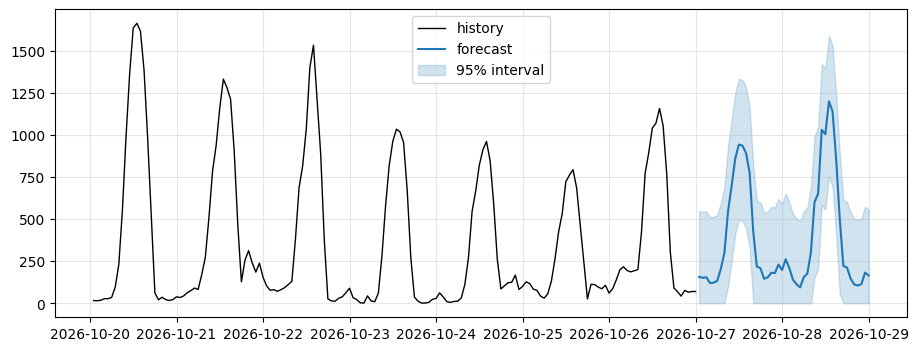

In [22]:
forecast = np.maximum(0, final_model.predict(X_future))

lower_95 = np.maximum(0, forecast + lower_error)
upper_95 = np.maximum(forecast, forecast + upper_error)

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [23]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved BONDAR_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.

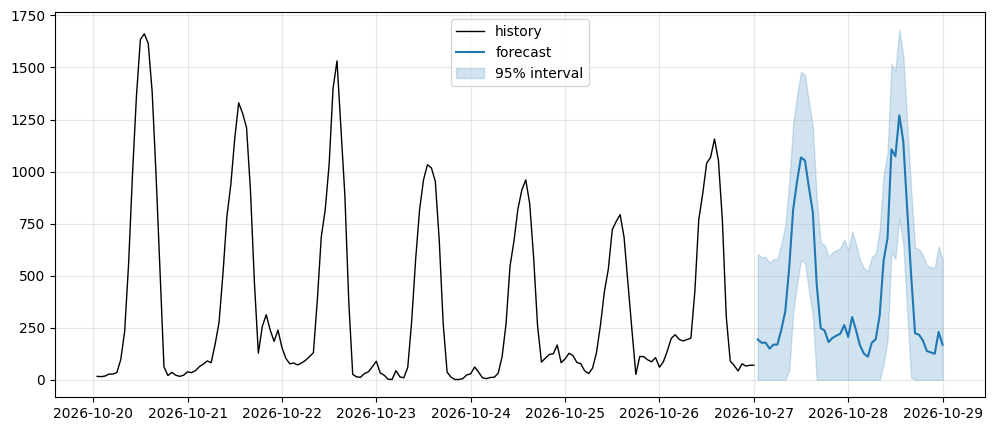

format OK
saved BONDAR_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
# Final submission using LightGBM

# Forecast and prediction intervals
forecast = np.maximum(0, lgb_forecast)
lower_95 = np.maximum(0, forecast + lower_error)
upper_95 = np.maximum(forecast, forecast + upper_error)

# Future timestamps
FUTURE = pd.to_datetime(weather_fc["ds"])

# Plot forecast and 95% prediction interval
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    data["ds"].iloc[-7 * 24:],
    data["y"].iloc[-7 * 24:],
    color="black",
    lw=1,
    label="history"
)

ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(
    FUTURE,
    lower_95,
    upper_95,
    color="tab:blue",
    alpha=0.2,
    label="95% interval"
)

ax.legend()
plt.show()


# Submission validation
def check_submission(sub):
    assert list(sub.columns) == [
        "ds", "forecast", "lower_95", "upper_95"
    ], "Wrong columns"

    assert len(sub) == 48, f"Expected 48 rows, got {len(sub)}"

    assert pd.to_datetime(sub["ds"]).notna().all()
    assert pd.to_datetime(sub["ds"]).equals(
        pd.Series(FUTURE).reset_index(drop=True)
    ), "Dates do not match FUTURE"

    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all()
    assert (sub["forecast"] >= 0).all()
    assert (sub["lower_95"] >= 0).all()
    assert (sub["lower_95"] <= sub["forecast"]).all()
    assert (sub["forecast"] <= sub["upper_95"]).all()

    print("format OK")


submission = pd.DataFrame({
    "ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"),
    "forecast": forecast,
    "lower_95": lower_95,
    "upper_95": upper_95
})

check_submission(submission)

# Save file
FILE = "BONDAR_project.csv"
submission.to_csv(FILE, index=False)

print("saved", FILE)

# Download in Google Colab
try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass